In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
import tensorflow as tf
from tensorflow.keras.layers import Input, Dense, Concatenate, Dropout
from sklearn.model_selection import train_test_split
import keras
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report

In [ ]:
#Data load
df = "/content/drive/MyDrive/Datasets/T5.xlsx"
df = pd.read_excel(df)

In [ ]:
#Data normalization
scaler = StandardScaler()
X = pd.DataFrame(scaler.fit_transform(df.iloc[:,3:]), columns=df.iloc[:,3:].columns)
#separate labels
labels = df['group'].to_numpy()

#number of classes
classes = 3

In [ ]:
visual_features = np.concatenate((X.iloc[:,1:7].to_numpy(), X.iloc[:,0].to_numpy().reshape(-1,1)), axis=1)
speech_features = np.concatenate((X.iloc[:,7:11].to_numpy(), X.iloc[:,0].to_numpy().reshape(-1,1)), axis=1)
pupl_features =  np.concatenate((X.iloc[:,11:17].to_numpy(), X.iloc[:,0].to_numpy().reshape(-1,1)), axis=1)

In [ ]:
visual_feature_dim = visual_features.shape[1]
speech_feature_dim = speech_features.shape[1]
pupl_feature_dim = pupl_features.shape[1]

In [ ]:
reg = 0.001
drop = 0.2

# Define input shapes for visual and speech features
visual_input_shape = (visual_feature_dim,)
speech_input_shape = (speech_feature_dim,)
pupl_input_shape = (pupl_feature_dim,)


# Define input layers for visual and speech features
visual_input = Input(shape=visual_input_shape, name='visual_input')
speech_input = Input(shape=speech_input_shape, name='speech_input')
pupl_input = Input(shape=pupl_input_shape, name='pupl_input')

# Visual features net
visual_net = Dense(128, activation='relu',kernel_regularizer=keras.regularizers.l1_l2(l1=0, l2=reg))(visual_input)
visual_net = Dropout(drop)(visual_net)
visual_net = Dense(64, activation='relu',kernel_regularizer=keras.regularizers.l1_l2(l1=0, l2=reg))(visual_net)


#Speech features net
speech_net = Dense(128, activation='relu',kernel_regularizer=keras.regularizers.l1_l2(l1=0, l2=reg))(speech_input)
speech_net = Dropout(drop)(speech_net)
speech_net = Dense(64,activation='relu',kernel_regularizer=keras.regularizers.l1_l2(l1=0, l2=reg))(speech_net)


#Pupl features net
pupl_net = Dense(128, activation='relu')(pupl_input)
pupl_net = Dropout(drop)(pupl_net)
pupl_net = Dense(64, activation='relu', kernel_regularizer=keras.regularizers.l1_l2(l1=0, l2=reg))(pupl_net)



# Concatenate the output of the two networks
concatenated_features = Concatenate()([visual_net, speech_net, pupl_net])

# Fusion layer (optional) to combine the features
fusion_layer = Dense(units=128, activation='relu',kernel_regularizer=keras.regularizers.l1_l2(l1=0, l2=reg))(concatenated_features)
fusion_layer = Dropout(drop)(fusion_layer)
fusion_layer = Dense(64, activation='relu',kernel_regularizer=keras.regularizers.l1_l2(l1=0, l2=reg))(fusion_layer)



# Output layer
output = Dense(units=classes, activation='softmax')(fusion_layer)  # Adjust activation and units as needed

# Create the model
model = tf.keras.Model(inputs=[visual_input, speech_input, pupl_input], outputs=output)

# Compile the model
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Print model summary
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)              ┃ Output Shape           ┃        Param # ┃ Connected to           ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩
│ visual_input (InputLayer) │ (None, 7)              │              0 │ -                      │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ speech_input (InputLayer) │ (None, 5)              │              0 │ -                      │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ pupl_input (InputLayer)   │ (None, 7)              │              0 │ -                      │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dense (Dense)             │ (None, 128)            │          1,024 │ visual_input[0][0]     │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dense_2 (Dense)           │ (None, 128)            │            768 │ speech_input[0][0]     │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dense_4 (Dense)           │ (None, 128)            │          1,024 │ pupl_input[0][0]       │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dropout (Dropout)         │ (None, 128)            │              0 │ dense[0][0]            │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dropout_1 (Dropout)       │ (None, 128)            │              0 │ dense_2[0][0]          │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dropout_2 (Dropout)       │ (None, 128)            │              0 │ dense_4[0][0]          │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dense_1 (Dense)           │ (None, 64)             │          8,256 │ dropout[0][0]          │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dense_3 (Dense)           │ (None, 64)             │          8,256 │ dropout_1[0][0]        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dense_5 (Dense)           │ (None, 64)             │          8,256 │ dropout_2[0][0]        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ concatenate (Concatenate) │ (None, 192)            │              0 │ dense_1[0][0],         │
│                           │                        │                │ dense_3[0][0],         │
│                           │                        │                │ dense_5[0][0]          │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dense_6 (Dense)           │ (None, 128)            │         24,704 │ concatenate[0][0]      │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dropout_3 (Dropout)       │ (None, 128)            │              0 │ dense_6[0][0]          │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dense_7 (Dense)           │ (None, 64)             │          8,256 │ dropout_3[0][0]        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dense_8 (Dense)           │ (None, 3)              │            195 │ dense_7[0][0]          │
└───────────────────────────┴────────────────────────┴────────────────┴────────────────────────┘

 Total params: 60,739 (237.26 KB)

 Trainable params: 60,739 (237.26 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Convert labels to one-hot encoding
labels_one_hot = tf.keras.utils.to_categorical(labels, num_classes=classes)

# Split data into training and testing sets
visual_train, visual_test, speech_train, speech_test, pupl_train, pupl_test, labels_train, labels_test = train_test_split(
    visual_features, speech_features, pupl_features, labels_one_hot, test_size=0.2, random_state=42
)

# Print shapes of training and testing sets
print("Training data shapes:")
print("Visual features:", visual_train.shape)
print("Speech features:", speech_train.shape)
print("Speech features:", pupl_train.shape)
print("Labels:", labels_train.shape)
print("\nTesting data shapes:")
print("Visual features:", visual_test.shape)
print("Speech features:", speech_test.shape)
print("Speech features:", pupl_test.shape)
print("Labels:", labels_test.shape)

Training data shapes:
Visual features: (5352, 7)
Speech features: (5352, 5)
Speech features: (5352, 7)
Labels: (5352, 3)

Testing data shapes:
Visual features: (1339, 7)
Speech features: (1339, 5)
Speech features: (1339, 7)
Labels: (1339, 3)


In [ ]:
from tensorflow.keras.callbacks import ModelCheckpoint

# Define a callback to save the best model
checkpoint_callback = ModelCheckpoint(filepath='T5_best_multimodel.keras',
                                      monitor='val_accuracy',
                                      save_best_only=True,
                                      mode='max')


In [ ]:
# model.save('T5_best_multimodel.h5', save_format='h5')
model.save('T5_best_multimodel.keras')

In [ ]:
# Train the model
history = model.fit(
    [visual_train, speech_train, pupl_train],
    labels_train,
    epochs=300,
    batch_size=32,
    validation_data=([visual_test, speech_test, pupl_test], labels_test),
    callbacks=[checkpoint_callback]
)

Epoch 1/300
168/168 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - accuracy: 0.5051 - loss: 1.4815 - val_accuracy: 0.5108 - val_loss: 1.3016
Epoch 2/300
168/168 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.5275 - loss: 1.2532 - val_accuracy: 0.5116 - val_loss: 1.1877
Epoch 3/300
168/168 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.5301 - loss: 1.1528 - val_accuracy: 0.5250 - val_loss: 1.1090
Epoch 4/300
168/168 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.5459 - loss: 1.0818 - val_accuracy: 0.5459 - val_loss: 1.0580
Epoch 5/300
168/168 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.5683 - loss: 1.0358 - val_accuracy: 0.5512 - val_loss: 1.0181
Epoch 6/300
168/168 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.5887 - loss: 0.9852 - val_accuracy: 0.5870 - val_loss: 0.9754
Epoch 7/300
168/168 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6052 - loss: 0.9608 - val_accuracy: 0.5855 - val_loss: 0.9608
Epoch 8/300
168/168 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6140 - loss: 0.9437 - val_acc

Text(0.5, 1.0, 'Training and validation accuracy')

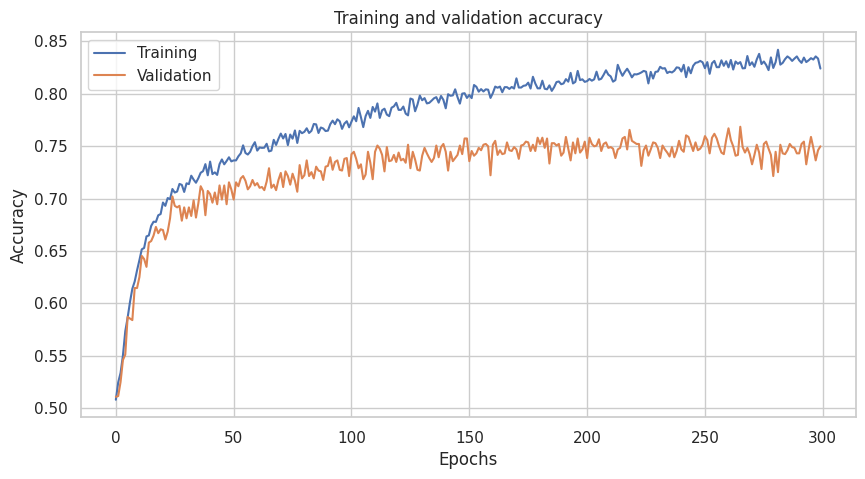

In [ ]:
Epochs = len(history.history['loss'])
#Plot accuracy of the model vs epochs
sns.set_theme(style='whitegrid')
plt.figure(figsize=(10,5),dpi=100)
plt.plot(range(Epochs),history.history['accuracy']);
plt.plot(range(Epochs),history.history['val_accuracy']);
#Label the figure
plt.legend(["Training", "Validation"])
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Training and validation accuracy")

In [ ]:
# Load the best model
best_model = tf.keras.models.load_model('T5_best_multimodel.keras')

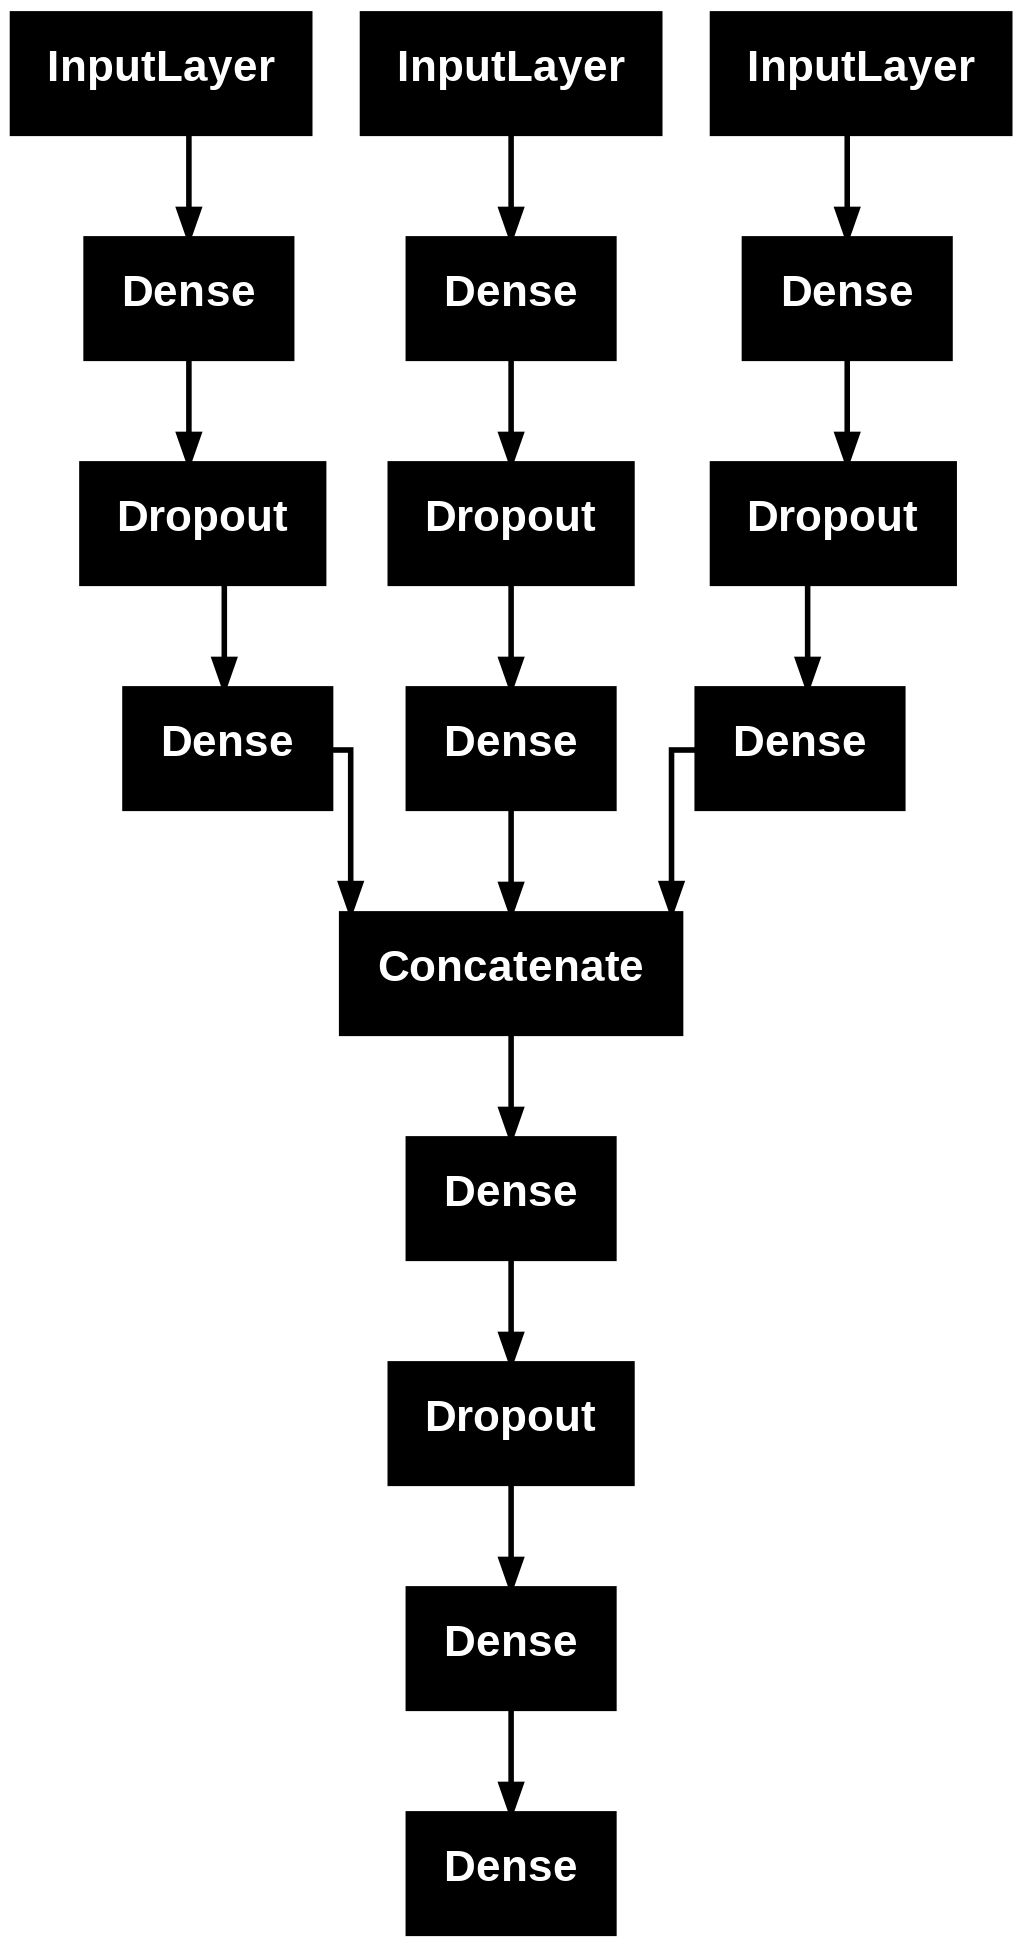

In [ ]:
keras.utils.plot_model(best_model)

In [ ]:
LABELS = ['Healthy', 'MCI', "Alzh"]

#Prediction from the model
pred_prob = best_model.predict([visual_test, speech_test, pupl_test])
ann_pred = np.argmax(pred_prob, axis=1)

#Classification report
print(classification_report(np.argmax(labels_test, axis=1), ann_pred,target_names=LABELS))

# #Call the function
# plot_confusion_matrix(y_test, ann_pred)

42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
              precision    recall  f1-score   support

     Healthy       0.78      0.83      0.80       664
         MCI       0.74      0.73      0.73       356
        Alzh       0.79      0.67      0.73       319

    accuracy                           0.77      1339
   macro avg       0.77      0.75      0.75      1339
weighted avg       0.77      0.77      0.77      1339



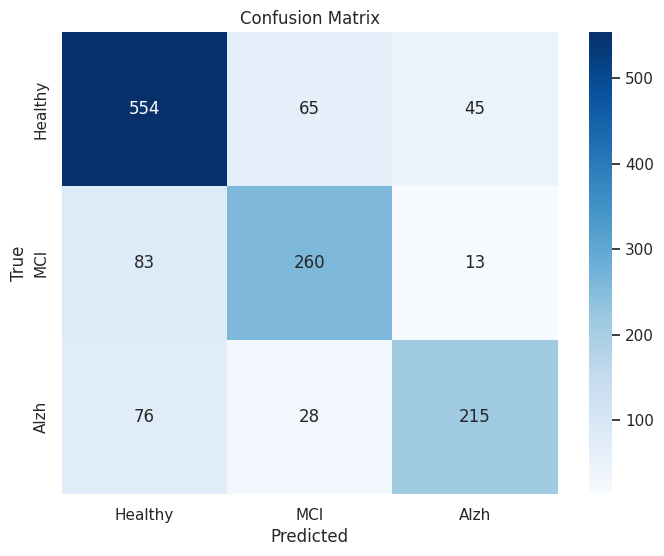

In [ ]:
from sklearn.metrics import confusion_matrix
# #Call the function
def plot_confusion_matrix(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(8,6))
    sns.heatmap(cm, annot=True, fmt="d", cmap='Blues', xticklabels=LABELS, yticklabels=LABELS)
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.title('Confusion Matrix')
    plt.show()

# Call the function to plot the confusion matrix
plot_confusion_matrix(np.argmax(labels_test, axis=1), ann_pred)

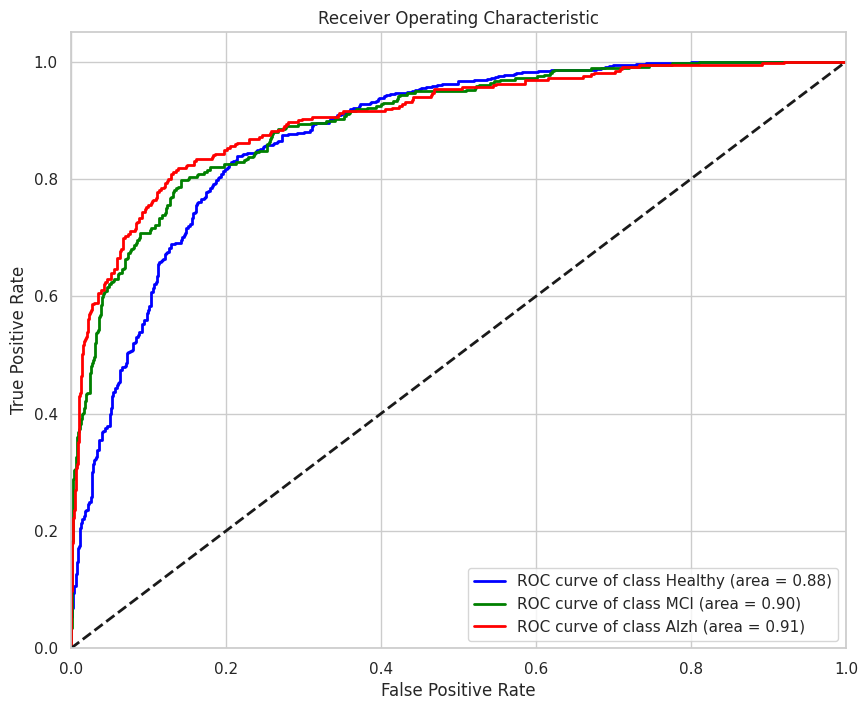

In [ ]:
from sklearn.metrics import roc_curve, auc
from tensorflow.keras.utils import to_categorical

labels_test_binarized = to_categorical(np.argmax(labels_test, axis=1), num_classes=len(LABELS))

plt.figure(figsize=(10, 8))
colors = ['blue', 'green', 'red']
for i, color in enumerate(colors):
    fpr, tpr, thresholds = roc_curve(labels_test_binarized[:, i], pred_prob[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, color=color, lw=2, label=f'ROC curve of class {LABELS[i]} (area = {roc_auc:.2f})')

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

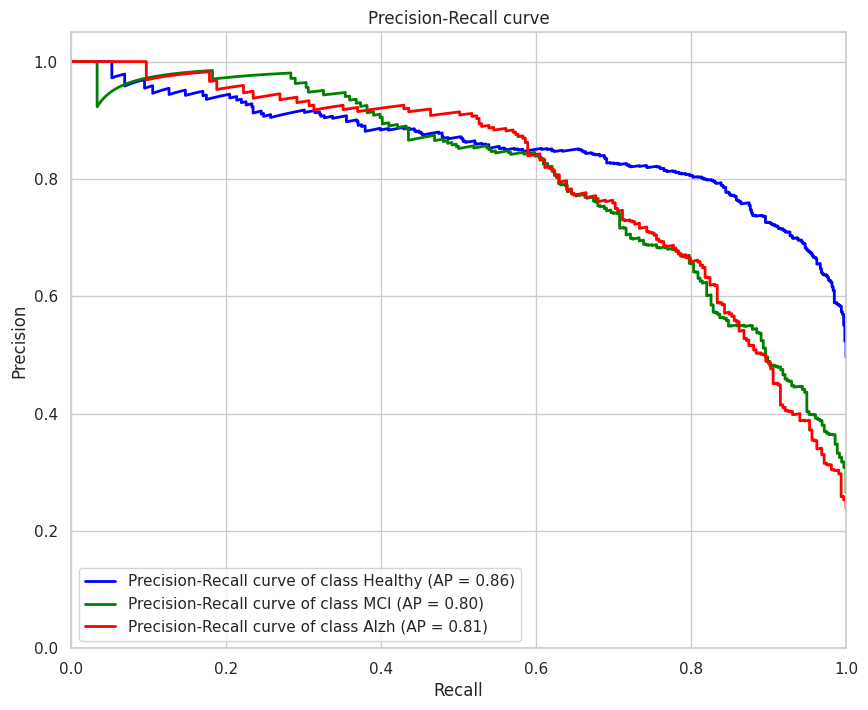

In [ ]:
from sklearn.metrics import precision_recall_curve, average_precision_score

plt.figure(figsize=(10, 8))
colors = ['blue', 'green', 'red']
for i, color in enumerate(colors):
    precision, recall, thresholds = precision_recall_curve(labels_test_binarized[:, i], pred_prob[:, i])
    average_precision = average_precision_score(labels_test_binarized[:, i], pred_prob[:, i])
    plt.plot(recall, precision, color=color, lw=2, label=f'Precision-Recall curve of class {LABELS[i]} (AP = {average_precision:.2f})')

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.ylim([0.0, 1.05])
plt.xlim([0.0, 1.0])
plt.title('Precision-Recall curve')
plt.legend(loc="lower left")
plt.show()

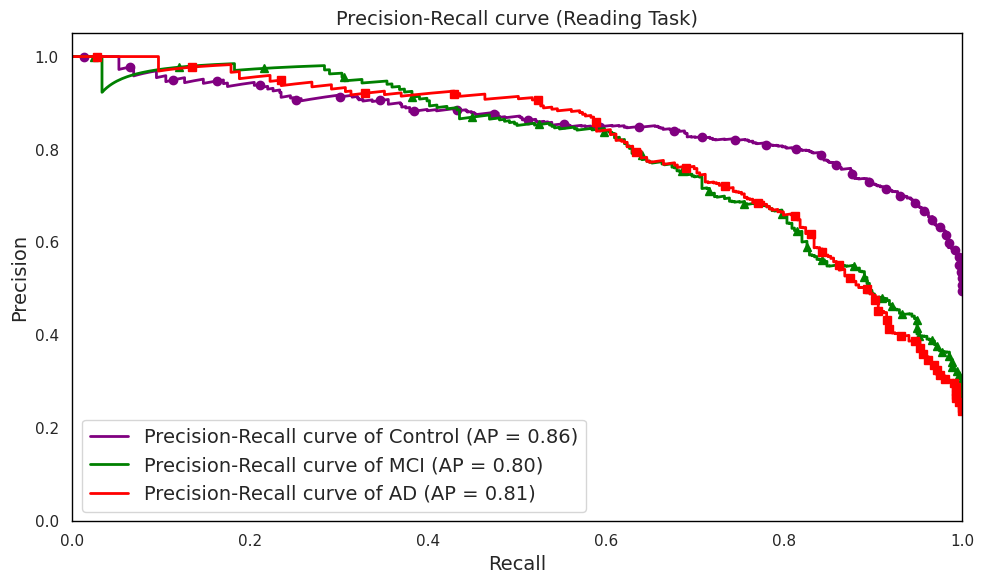

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from sklearn.metrics import precision_recall_curve, average_precision_score

plt.figure(figsize=(10, 6))
colors = ['purple', 'green', 'red']
markers = ['o', '^', 's']  # Circle, Triangle, Square
marker_interval = 35  # Plot marker every 10 points
labels = ['Control', 'MCI', 'AD']  # Updated labels

for i, (color, marker, label) in enumerate(zip(colors, markers, labels)):
    precision, recall, thresholds = precision_recall_curve(labels_test_binarized[:, i], pred_prob[:, i])
    average_precision = average_precision_score(labels_test_binarized[:, i], pred_prob[:, i])
    # Plot the main line
    plt.plot(recall, precision, color=color, lw=2, label=f'Precision-Recall curve of {label} (AP = {average_precision:.2f})')
    # Add markers at intervals
    plt.plot(recall[::marker_interval], precision[::marker_interval], linestyle='none', marker=marker, color=color)

plt.xlabel('Recall', fontsize=14)
plt.ylabel('Precision', fontsize=14)
plt.ylim([0.0, 1.05])
plt.xlim([0.0, 1.0])
plt.grid(False)
plt.title('Precision-Recall curve (Reading Task)', fontsize=14)
plt.legend(loc="lower left", fontsize=14)

ax = plt.gca()
for spine in ax.spines.values():
    spine.set_edgecolor('black')
    spine.set_linewidth(1)


plt.tight_layout()
plt.savefig("PRcurve.png", dpi=300)
plt.show()

# Code to download the image
from google.colab import files
files.download("PRcurve.png")